In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


import warnings
warnings.filterwarnings('ignore')


%matplotlib inline

print(" All libraries imported successfully!")


 All libraries imported successfully!


In [2]:
#  Load the dataset
df = pd.read_csv("C:/Users/HP/Desktop/adult 3.csv")

#  Preview the data
df.head()


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


In [3]:
# Check for standard missing values (NaN)
print(df.isnull().sum())

# Check for '?' placeholders in each column
for col in df.columns:
    if df[col].dtype == 'object':
        print(f"{col}: {(df[col] == '?').sum()} ? values")


age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
marital-status     0
occupation         0
relationship       0
race               0
gender             0
capital-gain       0
capital-loss       0
hours-per-week     0
native-country     0
income             0
dtype: int64
workclass: 2799 ? values
education: 0 ? values
marital-status: 0 ? values
occupation: 2809 ? values
relationship: 0 ? values
race: 0 ? values
gender: 0 ? values
native-country: 857 ? values
income: 0 ? values


In [4]:
import numpy as np

# Replace '?' with np.nan
df.replace('?', np.nan, inplace=True)

# Drop rows with missing values
df.dropna(inplace=True)

# Reset index
df.reset_index(drop=True, inplace=True)

# Confirm cleanup
print("Missing values after cleaning:\n", df.isnull().sum())


Missing values after cleaning:
 age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
marital-status     0
occupation         0
relationship       0
race               0
gender             0
capital-gain       0
capital-loss       0
hours-per-week     0
native-country     0
income             0
dtype: int64


In [6]:
from sklearn.preprocessing import LabelEncoder

# Create a LabelEncoder instance
le = LabelEncoder()

# List of categorical columns
cat_cols = ['workclass', 'education', 'marital-status', 'occupation',
            'relationship', 'race', 'gender', 'native-country', 'income']

# Apply label encoding to each column
for col in cat_cols:
    df[col] = le.fit_transform(df[col])

# Show the first few rows after encoding
df.head()


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,2,226802,1,7,4,6,3,2,1,0,0,40,37,0
1,38,2,89814,10,9,2,4,0,4,1,0,0,50,37,0
2,28,1,336951,6,12,2,10,0,4,1,0,0,40,37,1
3,24,2,369667,13,10,4,7,4,4,0,0,0,40,37,0
4,36,0,212465,8,13,2,0,0,4,1,0,0,40,37,0


In [23]:
# Better: remove outliers only from age, hours-per-week
selected_cols = ['age', 'hours-per-week']

def remove_outliers_iqr(df, cols):
    for col in cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]
    return df

# Reload original data and re-clean missing values first
df = df_original.copy()
df.dropna(inplace=True)

# Remove outliers only from selected columns
df = remove_outliers_iqr(df, selected_cols)

# Reset index
df.reset_index(drop=True, inplace=True)




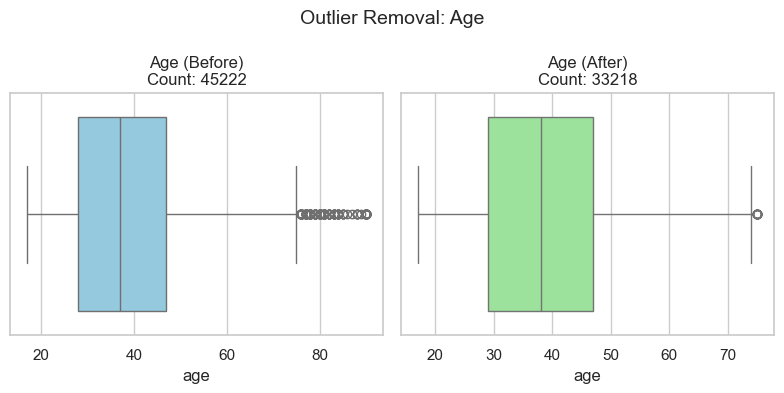

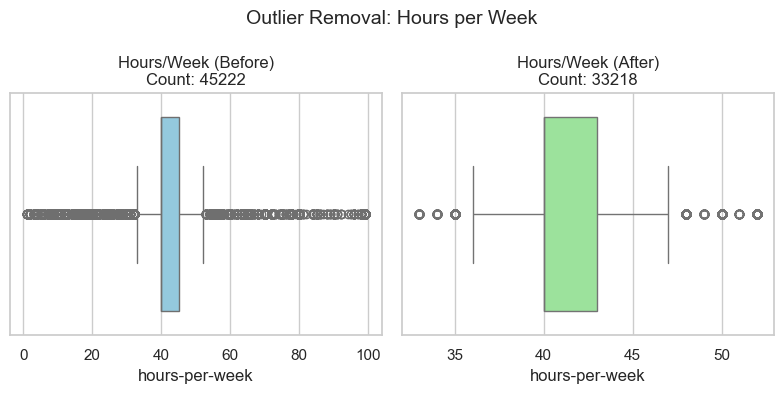

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# ------- Age -------
plt.figure(figsize=(8, 4))

# Before
plt.subplot(1, 2, 1)
sns.boxplot(x=df_original['age'], color='skyblue')
plt.title(f'Age (Before)\nCount: {len(df_original)}')

# After
plt.subplot(1, 2, 2)
sns.boxplot(x=df['age'], color='lightgreen')
plt.title(f'Age (After)\nCount: {len(df)}')

plt.suptitle("Outlier Removal: Age", fontsize=14)
plt.tight_layout()
plt.show()

# ------- Hours per Week -------
plt.figure(figsize=(8, 4))

# Before
plt.subplot(1, 2, 1)
sns.boxplot(x=df_original['hours-per-week'], color='skyblue')
plt.title(f'Hours/Week (Before)\nCount: {len(df_original)}')

# After
plt.subplot(1, 2, 2)
sns.boxplot(x=df['hours-per-week'], color='lightgreen')
plt.title(f'Hours/Week (After)\nCount: {len(df)}')

plt.suptitle("Outlier Removal: Hours per Week", fontsize=14)
plt.tight_layout()
plt.show()


In [24]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop('income', axis=1)
y = df['income']  # This is the encoded target

# Split data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Show the shapes
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)


Training set: (26574, 14)
Testing set: (6644, 14)


In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [27]:
categorical_cols = df.select_dtypes(include='object').columns
print(categorical_cols)


Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'gender', 'native-country', 'income'],
      dtype='object')


In [28]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in ['workclass', 'education', 'marital-status', 'occupation',
            'relationship', 'race', 'gender', 'native-country', 'income']:
    df[col] = le.fit_transform(df[col])


In [29]:
# Split features and target
X = df.drop('income', axis=1)
y = df['income']


In [30]:
from sklearn.model_selection import train_test_split

# 80-20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [33]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import joblib

# Define models
models = {
    'KNN': KNeighborsClassifier(),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(),
    'Gradient Boosting': GradientBoostingClassifier(),
    'SVM': SVC()
}


results = {}

# Train and evaluate each model
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    results[name] = accuracy
    print(f"{name} Accuracy: {accuracy:.4f}")
    print(classification_report(y_test, y_pred))

# Get the best model
best_model_name = max(results, key=results.get)
best_model = models[best_model_name]

print(f"\n✅ Best model: {best_model_name} with accuracy {results[best_model_name]:.4f}")

# Save the best model
joblib.dump(best_model, "best_model.pkl")
print("✅ Saved best model as best_model.pkl")


KNN Accuracy: 0.7508
              precision    recall  f1-score   support

           0       0.79      0.90      0.84      4900
           1       0.54      0.32      0.40      1744

    accuracy                           0.75      6644
   macro avg       0.67      0.61      0.62      6644
weighted avg       0.72      0.75      0.73      6644

Logistic Regression Accuracy: 0.7924
              precision    recall  f1-score   support

           0       0.82      0.93      0.87      4900
           1       0.67      0.41      0.51      1744

    accuracy                           0.79      6644
   macro avg       0.74      0.67      0.69      6644
weighted avg       0.78      0.79      0.77      6644

Random Forest Accuracy: 0.8432
              precision    recall  f1-score   support

           0       0.88      0.92      0.90      4900
           1       0.73      0.64      0.68      1744

    accuracy                           0.84      6644
   macro avg       0.80      0.78      

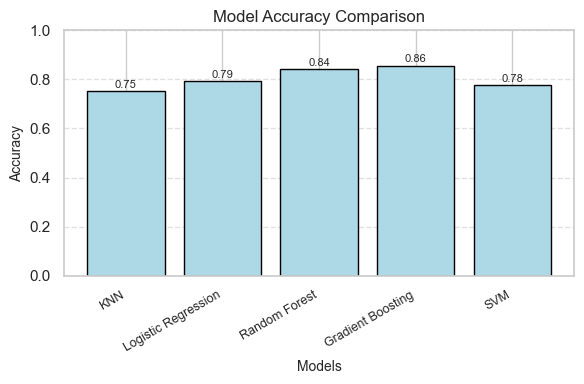

In [39]:
import matplotlib.pyplot as plt

# Model names and accuracies
model_names = list(results.keys())
accuracies = list(results.values())

# Plotting with small size but rotated x-labels for clarity
plt.figure(figsize=(6, 4))
bars = plt.bar(model_names, accuracies, color='lightblue', edgecolor='black')

# Add accuracy values on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, height + 0.005, f"{height:.2f}", ha='center', va='bottom', fontsize=8)

# Rotate x-axis labels
plt.xticks(rotation=30, ha='right', fontsize=9)

# Axis labels and title
plt.title('Model Accuracy Comparison', fontsize=12)
plt.ylabel('Accuracy', fontsize=10)
plt.xlabel('Models', fontsize=10)

# Add y-axis grid
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Improve layout
plt.tight_layout()
plt.show()


In [77]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score
import joblib

# Load dataset
df = pd.read_csv("C:/Users/HP/Desktop/adult 3.csv")

# Encode target
df['income'] = df['income'].apply(lambda x: 1 if x.strip() == '>50K' else 0)

# Select only the specified features + target
selected_features = ['age', 'workclass', 'education', 'occupation', 'capital-gain', 'hours-per-week', 'native-country']
X = df[selected_features]
y = df['income']

# Handle categorical columns by encoding them
X_encoded = pd.get_dummies(X, columns=['workclass', 'education', 'occupation', 'native-country'])

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

# Train Gradient Boosting model
model = GradientBoostingClassifier()
model.fit(X_train, y_train)

# Evaluate model
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

# Save model and columns used
joblib.dump(model, "best_model_selected_features.pkl")
joblib.dump(X_encoded.columns.tolist(), "selected_feature_columns.pkl")

accuracy


0.8374449790152523

In [78]:
import joblib
import pandas as pd

# Load trained model and columns
model = joblib.load("best_model_selected_features.pkl")
selected_columns = joblib.load("selected_feature_columns.pkl")

# Sample raw input (not encoded yet)
sample_raw = pd.DataFrame([{
    'age': 37,
    'workclass': 'Private',
    'education': 'Bachelors',
    'occupation': 'Prof-specialty',
    'capital-gain': 0,
    'hours-per-week': 40,
    'native-country': 'India'
}])

# Apply one-hot encoding
sample_encoded = pd.get_dummies(sample_raw)

# Align with training columns (add missing cols with 0)
for col in selected_columns:
    if col not in sample_encoded.columns:
        sample_encoded[col] = 0

# Ensure correct order
sample_encoded = sample_encoded[selected_columns]

# Predict
prediction = model.predict(sample_encoded)[0]
result = ">50K" if prediction == 1 else "<=50K"

print(f"📊 Predicted income: {result}")


📊 Predicted income: <=50K


In [ ]:
import streamlit as st
import pandas as pd
import joblib

# Load the trained model and selected columns
model = joblib.load("best_model_selected_features.pkl")
selected_columns = joblib.load("selected_feature_columns.pkl")

# Streamlit UI
st.title("💼 Employee Income Prediction App")
st.markdown("Predict whether a person's income is >50K or <=50K based on their demographic details.")

# Input fields
age = st.number_input("Age", min_value=18, max_value=90, value=30)
workclass = st.selectbox("Workclass", [
    "Private", "Self-emp-not-inc", "Self-emp-inc", "Federal-gov",
    "Local-gov", "State-gov", "Without-pay", "Never-worked"
])
education = st.selectbox("Education", [
    "Bachelors", "Some-college", "11th", "HS-grad", "Prof-school", "Assoc-acdm",
    "Assoc-voc", "9th", "7th-8th", "12th", "Masters", "1st-4th",
    "10th", "Doctorate", "5th-6th", "Preschool"
])
occupation = st.selectbox("Occupation", [
    "Tech-support", "Craft-repair", "Other-service", "Sales", "Exec-managerial",
    "Prof-specialty", "Handlers-cleaners", "Machine-op-inspct", "Adm-clerical",
    "Farming-fishing", "Transport-moving", "Priv-house-serv", "Protective-serv",
    "Armed-Forces"
])
capital_gain = st.number_input("Capital Gain", min_value=0, value=0)
hours_per_week = st.slider("Hours per Week", min_value=1, max_value=100, value=40)
native_country = st.selectbox("Native Country", [
    "United-States", "India", "Mexico", "Philippines", "Germany", "Canada",
    "England", "China", "Cuba", "Iran", "Other"
])

# Predict button
if st.button("Predict Income"):
    # Construct raw input DataFrame
    input_data = pd.DataFrame([{
        "age": age,
        "workclass": workclass,
        "education": education,
        "occupation": occupation,
        "capital-gain": capital_gain,
        "hours-per-week": hours_per_week,
        "native-country": native_country
    }])

    # One-hot encode
    input_encoded = pd.get_dummies(input_data)

    # Align with training columns
    for col in selected_columns:
        if col not in input_encoded.columns:
            input_encoded[col] = 0
    input_encoded = input_encoded[selected_columns]

    # Prediction
    prediction = model.predict(input_encoded)[0]
    result = ">50K" if prediction == 1 else "<=50K"

    # Output
    st.success(f"📊 Predicted Income: {result}")
